<a href="https://colab.research.google.com/github/Kavishka2401/GPTea/blob/C_1_Yield_Prediction/Machine_Learning_Pipeline/Preprocessing_and_ModelTraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import Google Drive to get the final dataset
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [47]:
import pandas as pd
import numpy as np

final_data_path = '/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Merged.csv'

# Load final data
final_data = pd.read_csv(final_data_path)
df = final_data.copy()

In [3]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.0 MB/s eta 0:00:00


In [87]:
# GENERAL PURPOSE LIBRARIES
import matplotlib.pyplot as plt
import seaborn as sns

# SKLEARN TOOLS
from sklearn.linear_model import Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer
from sklearn.inspection import permutation_importance

# XGBOOST
from xgboost import XGBRegressor

# CATBOOST
from catboost import CatBoostRegressor

# Neural Networks
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [5]:
import joblib
import os

## **Data Preprocessing**

### Remove Missing Rows

In [48]:
# Keep rows where YPH is not missing
df = df[df['YPH'].notna()]

### Data Type Conversion

In [49]:
month_map = {
    'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,
    'July':7,'August':8,'September':9,'October':10,'November':11,'December':12
}
df['Month'] = df['Month'].map(month_map)

### Remove irrelevant columns

In [50]:
df = df.drop(columns=['Month'])

In [51]:
# Remove highly correlated features
df = df.drop(columns=['temperature_2m_min',
                      'temperature_2m_max',
                      'relative_humidity_2m_min',
                      'relative_humidity_2m_max',
                      'wind_speed_10m_max',
                      'precipitation_sum',
                      'UT925',
                      'BioShakthi',
                      'Zinc',
                      'sunshine_duration',
                      'relative_humidity_2m_mean'])

# Display remaining columns to verify
print("Remaining columns after dropping redundant weather features:")
print(df.columns)

Remaining columns after dropping redundant weather features:
Index(['Year', 'YPH', 'T200', 'U709', 'Epson Salt', 'Dolomite', 'Urea',
       'Compost', 'BioShield', 'temperature_2m_mean', 'rain_sum',
       'wind_speed_10m_mean', 'et0_fao_evapotranspiration'],
      dtype='object')


### Feature Engineering

In [52]:
df['Dolomite_moisture'] = (
    df['Dolomite'] * (df['rain_sum'] - df['et0_fao_evapotranspiration'])
)

In [53]:
# Define final file path
final_data_path = "/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Preprocessed.csv"

# Save the preprocessed DataFrame
df.to_csv(final_data_path, index=False)

print(f"Preprocessed dataset saved successfully at:\n{final_data_path}")

Preprocessed dataset saved successfully at:
/content/drive/MyDrive/DSGP_DOCS/Datasets/Final_Data_Preprocessed.csv


# **CatBoost**

### Model Based Preprocessing

In [60]:
# Create copy
df_catboost = df.copy()

# Feature Engineering
df_catboost['Year_trend'] = df_catboost['Year'] - df_catboost['Year'].min()

# YPH lags
for lag in [1, 12]:
    df_catboost[f'YPH_lag{lag}'] = df_catboost['YPH'].shift(lag).bfill()

# Fertilizer lags
for fert in ['Compost']:
    df_catboost[f'{fert}_lag1'] = df_catboost[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_catboost.columns if col not in ['YPH', 'Year', 'Compost']]

# Walk Forward Validation test years
all_years = sorted(df_catboost['Year'].unique())
test_years = [y for y in all_years if all(ty in all_years for ty in [y-3, y-2, y-1])]

# Data Augmentation
def add_gaussian_noise(X, y, noise_std=0.03, n_augmentations=2):
    X_aug = [X.values.copy()]
    y_aug = [y.values.copy()]

    for _ in range(n_augmentations):
        noise = np.random.normal(0, noise_std * X.std(), X.shape)

        # Reduce noise for lag features
        lag_cols = [col for col in X.columns if 'YPH_lag' in col]
        for col in lag_cols:
            noise[:, X.columns.get_loc(col)] *= 0.7

        X_aug.append(X.values + noise)
        y_noise = np.random.normal(0, noise_std * 0.5 * y.std(), y.shape)
        y_aug.append(y.values + y_noise)

    return np.vstack(X_aug), np.hstack(y_aug)

### Model Training

In [61]:
train_results = []
test_results = []

for test_year in test_years:

    train_years = [test_year - 3, test_year - 2, test_year - 1]

    train_df = df_catboost[df_catboost['Year'].isin(train_years)]
    test_df  = df_catboost[df_catboost['Year'] == test_year]

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    # Augment training data
    X_train_aug, y_train_aug = add_gaussian_noise(X_train, y_train)

    # Model
    model = CatBoostRegressor(
        iterations=300,
        depth=3,
        learning_rate=0.025,
        l2_leaf_reg=15,
        min_data_in_leaf=25,
        subsample=0.7,
        random_strength=1.0,
        loss_function='RMSE',
        random_seed=42,
        verbose=False
    )

    # Training
    model.fit(
        X_train_aug, y_train_aug,
        eval_set=(X_test, y_test),
        early_stopping_rounds=50
    )

    # Predictions
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)

    # Store metrics for evaluation
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'train_years': train_years,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  3.823817  2.871011  14.621578  0.974704
1  2021  3.063520  2.305997   9.385153  0.984161
2  2022  2.588976  1.805435   6.702799  0.989570
3  2023  2.643225  1.873899   6.986638  0.989729
4  2024  2.680095  1.903966   7.182910  0.989480
5  2025  2.579842  1.798333   6.655587  0.990289

TEST METRICS PER YEAR
   year         train_years       rmse       mae         mse        r2
0  2020  [2017, 2018, 2019]  10.239299  7.998572  104.843251  0.826249
1  2021  [2018, 2019, 2020]  12.918668  9.514120  166.891990  0.729133
2  2022  [2019, 2020, 2021]   9.599044  6.237723   92.141654  0.850453
3  2023  [2020, 2021, 2022]   8.185216  5.161073   66.997766  0.891262
4  2024  [2021, 2022, 2023]   8.974476  6.275917   80.541213  0.869831
5  2025  [2022, 2023, 2024]  10.519832  7.163873  110.666870  0.821142

Average Train Metrics
rmse    2.896579
mae     2.093107
mse     8.589111
r2      0.986322
dtype: float64

Averag

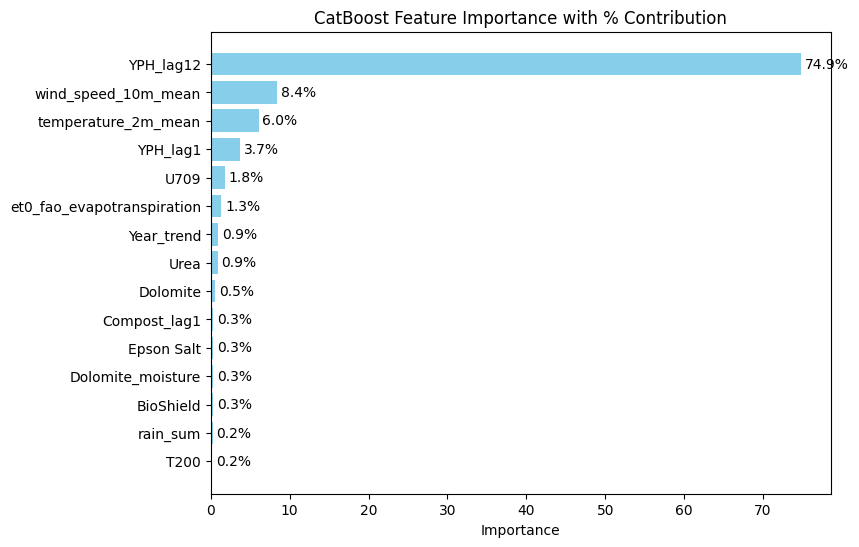

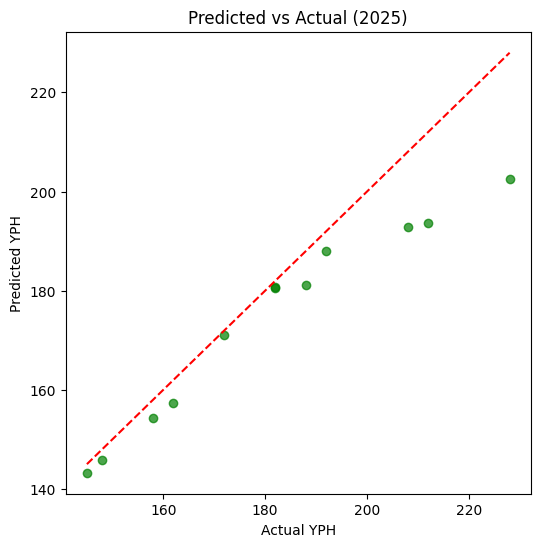

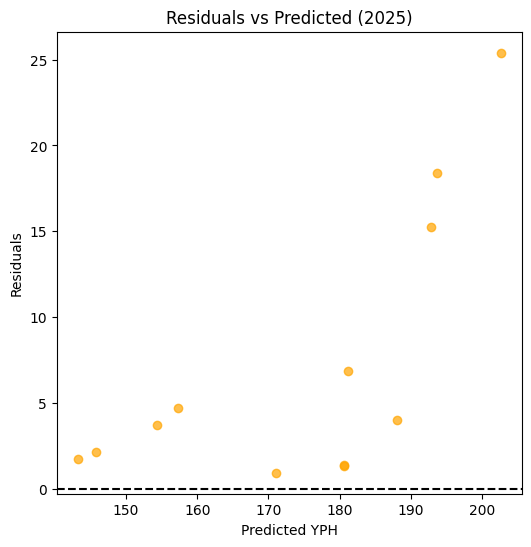

In [62]:
# Results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print Metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAverage Train Metrics")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())

print("\nAverage Test Metrics")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature Importance
feature_importance = pd.DataFrame({
    'feature': features,
    'importance': model.get_feature_importance()
})

# Calculate percentage contribution
feature_importance['percentage'] = (feature_importance['importance'] / feature_importance['importance'].sum()) * 100
feature_importance = feature_importance.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(feature_importance['feature'], feature_importance['importance'], color='skyblue')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("CatBoost Feature Importance with % Contribution")

# Percentage labels to bars
for bar, pct in zip(bars, feature_importance['percentage']):
    plt.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')

plt.show()

# Predicted vs Actual Plot
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_test_pred, color='green', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linestyle='--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({test_year})")
plt.show()

# Residuals vs Predicted Plot
residuals = y_test - y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(y_test_pred, residuals, color='orange', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({test_year})")
plt.show()

### Save Model

In [57]:
# Path to save
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/catboost_model.cbm'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save CatBoost model
model.save_model(save_path)
print(f"CatBoost model saved at: {save_path}")

CatBoost model saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/catboost_model.cbm


# **XGBoost**

### Model Based Preprocessing

In [63]:
# Create copy
df_xgb = df.copy()

# YPH lags (1, 6, 12 months)
for lag in [1, 12]:
    df_xgb[f'YPH_lag{lag}'] = df_xgb['YPH'].shift(lag).bfill()

# Fertilizer lags (1 month)
for fert in ['Compost']:
    df_xgb[f'{fert}_lag1'] = df_xgb[fert].shift(1).fillna(0)

# Target and features
target = 'YPH'
features = [col for col in df_xgb.columns if col not in ['YPH', 'Year','Compost']]

# Settings
TEST_YEARS = sorted(df_xgb[df_xgb['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3

### Model Training

In [64]:
# Clear previous results
train_results = []
test_results  = []

# Store last pipeline for plotting
last_pipeline = None

for test_year in TEST_YEARS:
    # Define train years
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]
    train_df = df_xgb[df_xgb['Year'].isin(train_years)].copy()
    test_df  = df_xgb[df_xgb['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]
    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # XGBoost pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('xgb', XGBRegressor(
            n_estimators=200,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.7,
            colsample_bytree=0.7,
            reg_alpha=1.0,
            reg_lambda=10.0,
            objective='reg:squarederror',
            random_state=42
        ))
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Save metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

    # Last pipeline for plots
    last_pipeline = pipeline
    last_y_test = y_test
    last_y_test_pred = y_test_pred

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  4.132749  2.332312  17.079613  0.970452
1  2021  3.578135  1.595389  12.803051  0.978392
2  2022  3.598186  1.947940  12.946941  0.979855
3  2023  3.745379  1.750853  14.027864  0.979378
4  2024  3.732226  1.702852  13.929509  0.979600
5  2025  3.641009  1.742633  13.256947  0.980657

TEST METRICS PER YEAR
   year       rmse       mae         mse        r2
0  2020  11.685824  8.592957  136.558472  0.773689
1  2021  13.063564  9.261154  170.656693  0.723022
2  2022  11.618912  7.535149  134.999115  0.780895
3  2023   9.746958  6.092381   95.003197  0.845809
4  2024  10.243689  7.087668  104.933159  0.830409
5  2025  12.205696  9.098586  148.979019  0.759223

AVERAGE TRAIN METRICS
rmse     3.737947
mae      1.845330
mse     14.007321
r2       0.978055
dtype: float64

AVERAGE TEST METRICS
rmse     11.427440
mae       7.944649
mse     131.854942
r2        0.785508
dtype: float64


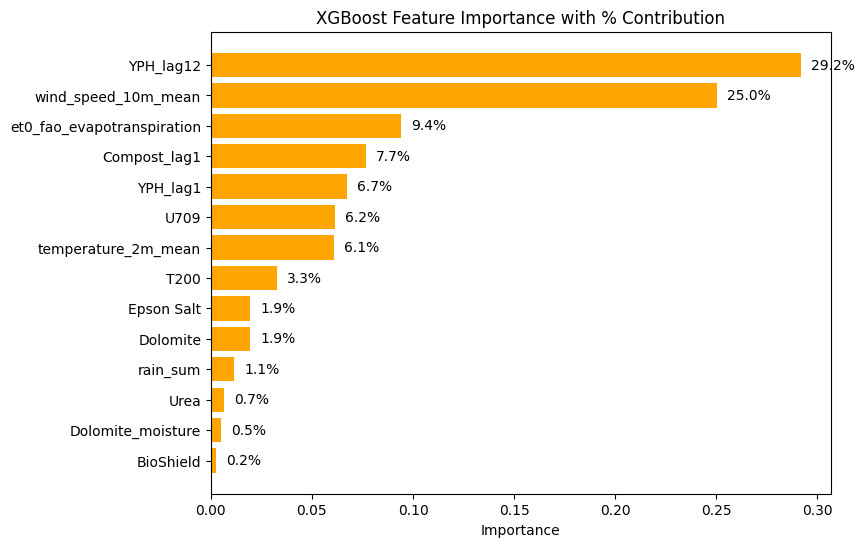

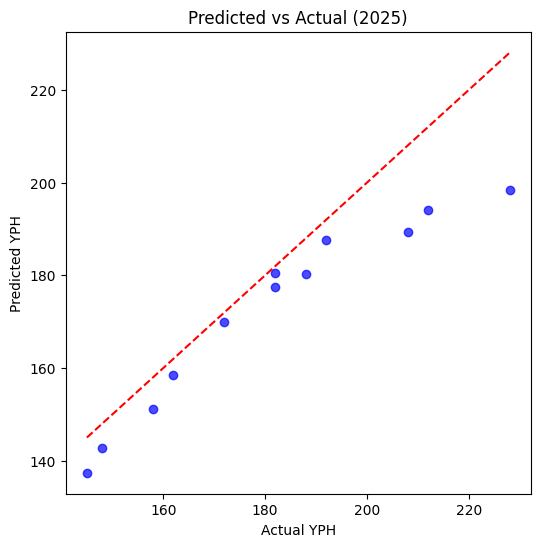

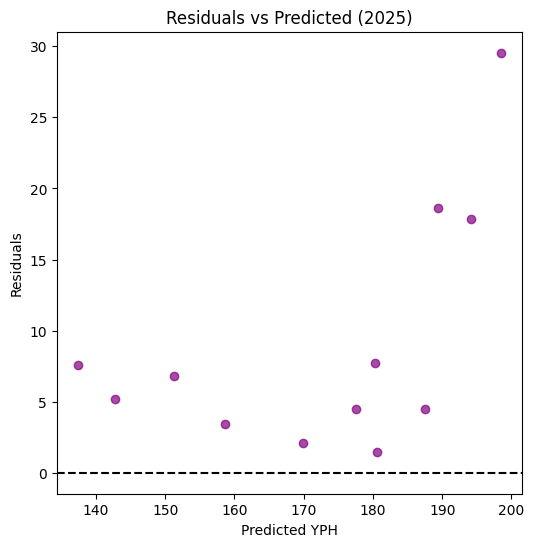

In [65]:
# Convert metrics to DataFrame
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())

print("\nAVERAGE TEST METRICS")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature importance with percentages
xgb_model = last_pipeline.named_steps['xgb']
feat_imp = pd.DataFrame({
    'feature': features,
    'importance': xgb_model.feature_importances_
})
feat_imp['percentage'] = (feat_imp['importance'] / feat_imp['importance'].sum()) * 100
feat_imp = feat_imp.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(feat_imp['feature'], feat_imp['importance'], color='orange')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("XGBoost Feature Importance with % Contribution")
# Add percentage labels
for bar, pct in zip(bars, feat_imp['percentage']):
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')
plt.show()

# Predicted vs Actual
plt.figure(figsize=(6,6))
plt.scatter(last_y_test, last_y_test_pred, alpha=0.7, color='blue')
plt.plot([last_y_test.min(), last_y_test.max()],
         [last_y_test.min(), last_y_test.max()],
         'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({TEST_YEARS[-1]})")
plt.show()

# Residuals vs Predicted
residuals = last_y_test - last_y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(last_y_test_pred, residuals, alpha=0.7, color='purple')
plt.axhline(0, linestyle='--', color='black')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({TEST_YEARS[-1]})")
plt.show()

### Save Model

In [66]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/xgb_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the XGBoost model (from pipeline)
joblib.dump(last_pipeline, save_path)
print(f"XGBoost pipeline saved at: {save_path}")

XGBoost pipeline saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/xgb_model.pkl


# **Random Forest**

### Model Based Preprocessing

In [67]:
# Create a copy of the dataframe
df_rf = df.copy()

# Create lag features for YPH (1, 6, 12 months)
for lag in [1, 12]:
    df_rf[f'YPH_lag{lag}'] = df_rf['YPH'].shift(lag).bfill()

# Create lag features for fertilizers (1-month lag)
for fert in ['Compost']:
    df_rf[f'{fert}_lag1'] = df_rf[fert].shift(1).fillna(0)

# Define target and features
target = 'YPH'
features = [col for col in df_rf.columns if col not in ['YPH', 'Year','Compost']]

# Walk-forward validation setup
TEST_YEARS = sorted(df_rf[df_rf['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3

# Clear previous results
train_results = []
test_results  = []

### Model Training

In [68]:
# Walk-forward validation training
for test_year in TEST_YEARS:
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]

    train_df = df_rf[df_rf['Year'].isin(train_years)].copy()
    test_df  = df_rf[df_rf['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]
    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # Random Forest pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('rf', RandomForestRegressor(
            n_estimators=300,
            max_depth=6,
            min_samples_leaf=5,
            max_features='sqrt',
            random_state=42
        ))
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Store metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

    # Keep last pipeline for evaluation/plots
    last_pipeline = pipeline
    last_y_test = y_test
    last_y_test_pred = y_test_pred

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year       rmse       mae         mse        r2
0  2020  12.705194  9.614206  161.421952  0.720733
1  2021  11.364986  8.374434  129.162917  0.782011
2  2022  12.752607  9.542122  162.628984  0.746950
3  2023  13.767876  9.955666  189.554413  0.721343
4  2024  12.614926  9.564781  159.136355  0.766938
5  2025  12.155778  8.832305  147.762933  0.784399

TEST METRICS PER YEAR
   year       rmse        mae         mse        r2
0  2020  18.841145  15.060278  354.988734  0.411695
1  2021  21.641118  16.535058  468.337996  0.239882
2  2022  21.563340  15.035850  464.977633  0.245336
3  2023  19.381982  15.323064  375.661228  0.390298
4  2024  19.479101  14.379713  379.435363  0.386764
5  2025  20.346473  15.302476  413.978978  0.330936

AVERAGE TRAIN METRICS
rmse     12.560228
mae       9.313919
mse     158.277925
r2        0.753729
dtype: float64

AVERAGE TEST METRICS
rmse     20.208860
mae      15.272740
mse     409.563322
r2        0.334152
dtype: float64


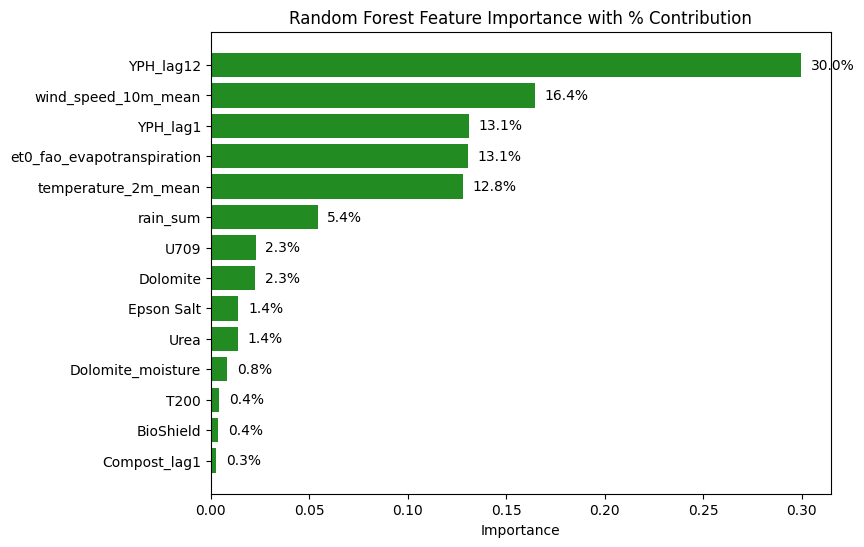

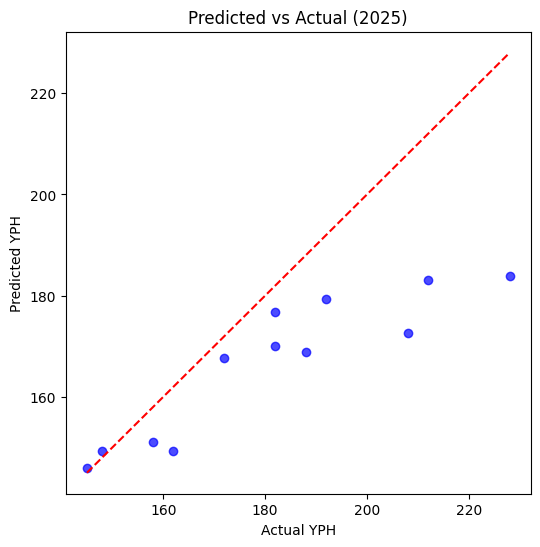

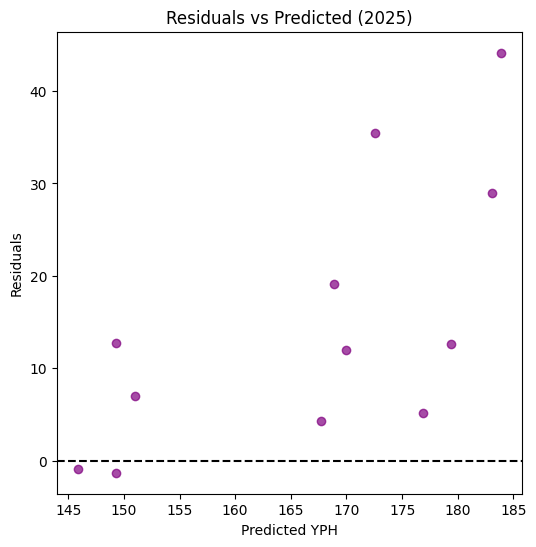

In [69]:
# Convert metrics to DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)
print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df[['rmse','mae','mse','r2']].mean())
print("\nAVERAGE TEST METRICS")
print(test_metrics_df[['rmse','mae','mse','r2']].mean())

# Feature importance
rf_model = last_pipeline.named_steps['rf']
feat_imp = pd.DataFrame({
    'feature': features,
    'importance': rf_model.feature_importances_
})
feat_imp['percentage'] = (feat_imp['importance'] / feat_imp['importance'].sum()) * 100
feat_imp = feat_imp.sort_values(by='importance', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(feat_imp['feature'], feat_imp['importance'], color='forestgreen')
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance with % Contribution")
for bar, pct in zip(bars, feat_imp['percentage']):
    plt.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2, f"{pct:.1f}%", va='center')
plt.show()

# Predicted vs Actual
plt.figure(figsize=(6,6))
plt.scatter(last_y_test, last_y_test_pred, color='blue', alpha=0.7)
plt.plot([last_y_test.min(), last_y_test.max()], [last_y_test.min(), last_y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({TEST_YEARS[-1]})")
plt.show()

# Residuals vs Predicted
residuals = last_y_test - last_y_test_pred
plt.figure(figsize=(6,6))
plt.scatter(last_y_test_pred, residuals, color='purple', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({TEST_YEARS[-1]})")
plt.show()

### Save Model

In [70]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/random_forest_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save pipeline
joblib.dump(last_pipeline, save_path)
print(f"Random Forest model saved at: {save_path}")

Random Forest model saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/random_forest_model.pkl


# **LASSO**

### Model Based Preprocessing

In [71]:
# Create copy
df_lasso = df.copy()

# Create lag features for YPH
for lag in [1, 12]:
    df_lasso[f'YPH_lag{lag}'] = df_lasso['YPH'].shift(lag).bfill()

# Create lag features for fertilizers (1-month lag)
for fert in ['Compost']:
    df_lasso[f'{fert}_lag1'] = df_lasso[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_lasso.columns if col not in ['YPH', 'Year','Compost']]

# Walk-forward validation settings
TEST_YEARS = sorted(df_lasso[df_lasso['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3
ALPHA = 1.0

### Model Training

In [72]:
train_results = []
test_results  = []

for test_year in TEST_YEARS:

    # Rolling 3-year training window
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]

    train_df = df_lasso[df_lasso['Year'].isin(train_years)].copy()
    test_df  = df_lasso[df_lasso['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # Lasso Regression Pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('lasso', Lasso(alpha=ALPHA, random_state=42, max_iter=10000))
    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Store metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  7.706827  5.616714  59.395181  0.897244
1  2021  3.516468  2.383855  12.365550  0.979131
2  2022  1.624778  1.436632   2.639904  0.995892
3  2023  1.609457  1.171200   2.590352  0.996192
4  2024  1.114037  0.876257   1.241078  0.998182
5  2025  1.114051  0.878635   1.241109  0.998189

TEST METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  9.535224  7.927519  90.920488  0.849322
1  2021  4.213653  3.435532  17.754873  0.971184
2  2022  0.957263  0.956841   0.916352  0.998513
3  2023  0.839778  0.786702   0.705227  0.998855
4  2024  1.548916  1.149330   2.399140  0.996123
5  2025  1.122589  0.906056   1.260206  0.997963

AVERAGE TRAIN METRICS
year    2022.500000
rmse       2.780936
mae        2.060549
mse       13.245529
r2         0.977472
dtype: float64

AVERAGE TEST METRICS
year    2022.500000
rmse       3.036237
mae        2.526997
mse       18.992714
r2         0.968660
dtype: 

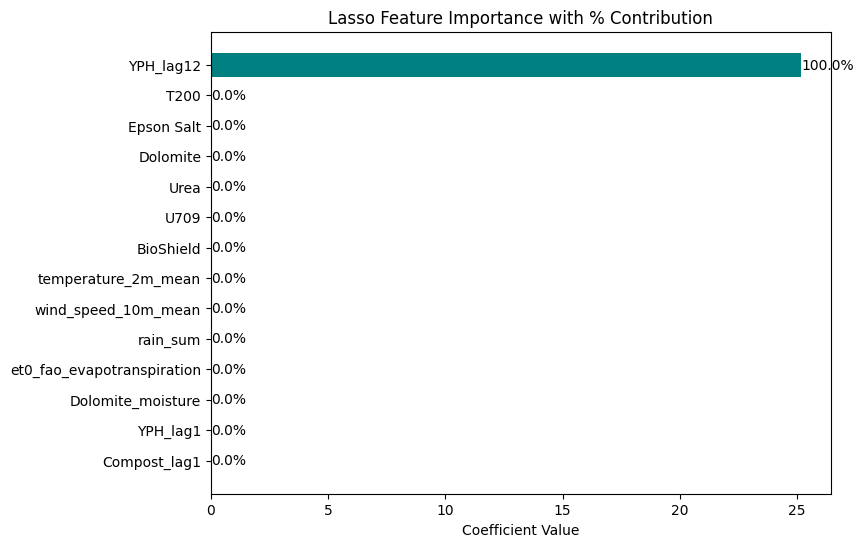

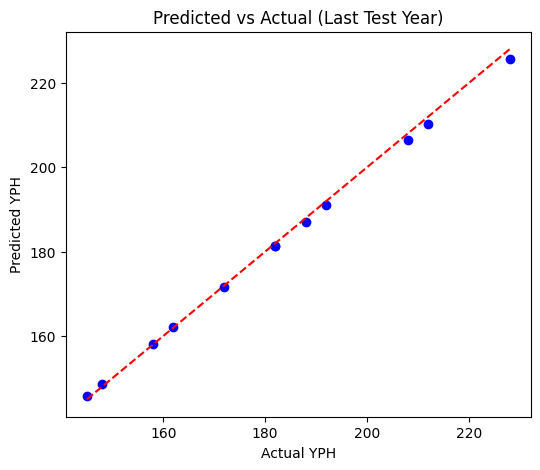

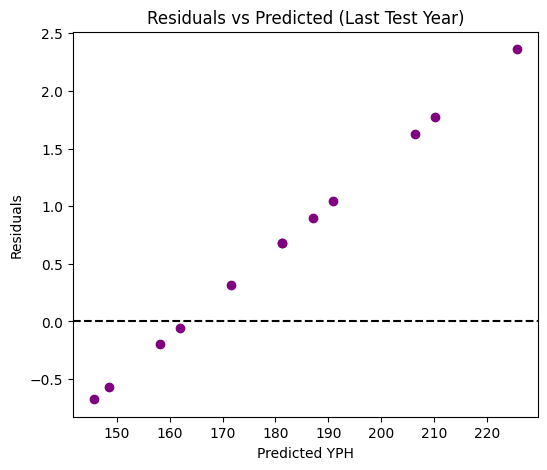

In [73]:
# Create results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

# Print metrics
print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df.mean(numeric_only=True))

print("\nAVERAGE TEST METRICS")
print(test_metrics_df.mean(numeric_only=True))

# Feature Importance (Lasso coefficients)
lasso_model = pipeline.steps[-1][1]

# Create DataFrame
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': lasso_model.coef_
})

# Absolute value for sorting
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df['percentage'] = (coef_df['abs_coef'] / coef_df['abs_coef'].sum()) * 100

# Sort descending by absolute coefficient
coef_df = coef_df.sort_values(by='abs_coef', ascending=False)

# Plot feature importance with % contribution
plt.figure(figsize=(8,6))
bars = plt.barh(coef_df['feature'], coef_df['coefficient'], color='teal')
plt.gca().invert_yaxis()
plt.xlabel("Coefficient Value")
plt.title("Lasso Feature Importance with % Contribution")

# Add percentage labels to bars
for bar, pct in zip(bars, coef_df['percentage']):
    plt.text(bar.get_width() + np.sign(bar.get_width())*0.02,
             bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')

plt.show()

# Predicted vs Actual
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_test_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title("Predicted vs Actual (Last Test Year)")
plt.show()

# Residuals vs Predicted
residuals = y_test - y_test_pred
plt.figure(figsize=(6,5))
plt.scatter(y_test_pred, residuals, color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Last Test Year)")
plt.show()

### Save Model

In [74]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/lasso_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the last trained Lasso pipeline
joblib.dump(pipeline, save_path)
print(f"Lasso pipeline saved at: {save_path}")

Lasso pipeline saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/lasso_model.pkl


# **Ridge Regressor**

### Model Based Preprocessing

In [77]:
# Create copy
df_ridge = df.copy()

# YPH lags (1,12)
for lag in [1, 12]:
    df_ridge[f'YPH_lag{lag}'] = df_ridge['YPH'].shift(lag).bfill()

# Fertilizer lags (1 month)
for fert in ['Compost']:
    df_ridge[f'{fert}_lag1'] = df_ridge[fert].shift(1).fillna(0)

# TARGET & FEATURES
target = 'YPH'
features = [col for col in df_ridge.columns if col not in ['YPH', 'Year','Compost']]

# SETTINGS
TEST_YEARS = sorted(df_ridge[df_ridge['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3
ALPHA = 5.0

# Metric storage
train_results = []
test_results  = []

### Model Training

In [78]:
# Walk-Forward Validation
for test_year in TEST_YEARS:

    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]

    train_df = df_ridge[df_ridge['Year'].isin(train_years)].copy()
    test_df  = df_ridge[df_ridge['Year'] == test_year].copy()

    X_train = train_df[features]
    y_train = train_df[target]

    X_test = test_df[features]
    y_test = test_df[target]

    print(f"Test Year {test_year} | Train Years {train_years}")

    # Ridge pipeline
    pipeline = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('ridge', Ridge(alpha=ALPHA, random_state=42))
    ])

    # Train
    pipeline.fit(X_train, y_train)

    # Predictions
    y_train_pred = pipeline.predict(X_train)
    y_test_pred  = pipeline.predict(X_test)

    # Store metrics
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

Test Year 2020 | Train Years [np.int64(2017), np.int64(2018), np.int64(2019)]
Test Year 2021 | Train Years [np.int64(2018), np.int64(2019), np.int64(2020)]
Test Year 2022 | Train Years [np.int64(2019), np.int64(2020), np.int64(2021)]
Test Year 2023 | Train Years [np.int64(2020), np.int64(2021), np.int64(2022)]
Test Year 2024 | Train Years [np.int64(2021), np.int64(2022), np.int64(2023)]
Test Year 2025 | Train Years [np.int64(2022), np.int64(2023), np.int64(2024)]


### Model Evaluation and Visualization


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  6.684277  5.305921  44.679561  0.922703
1  2021  3.992815  3.100349  15.942570  0.973094
2  2022  3.752233  2.995246  14.079253  0.978093
3  2023  3.765817  2.988370  14.181379  0.979152
4  2024  3.804398  2.999242  14.473443  0.978803
5  2025  3.710238  2.901221  13.765866  0.979914

TEST METRICS PER YEAR
   year       rmse       mae         mse        r2
0  2020   9.006636  6.955442   81.119499  0.865565
1  2021  10.101019  8.751309  102.030580  0.834403
2  2022   5.298978  4.612633   28.079163  0.954427
3  2023   4.116057  3.757037   16.941926  0.972503
4  2024   4.485343  3.559449   20.118302  0.967485
5  2025   6.761769  5.661592   45.721517  0.926106

AVERAGE TRAIN METRICS
year    2022.500000
rmse       4.284963
mae        3.381725
mse       19.520345
r2         0.968626
dtype: float64

AVERAGE TEST METRICS
year    2022.500000
rmse       6.628300
mae        5.549577
mse       49.001831
r2         0.

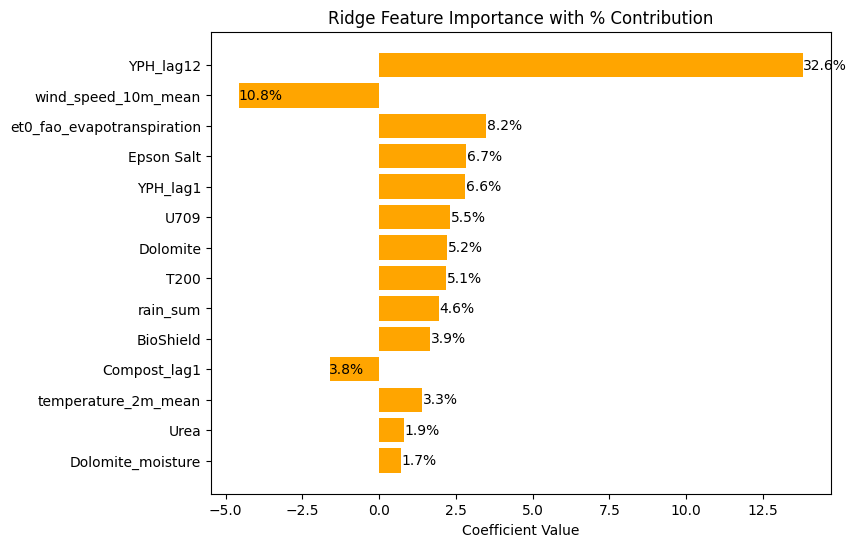

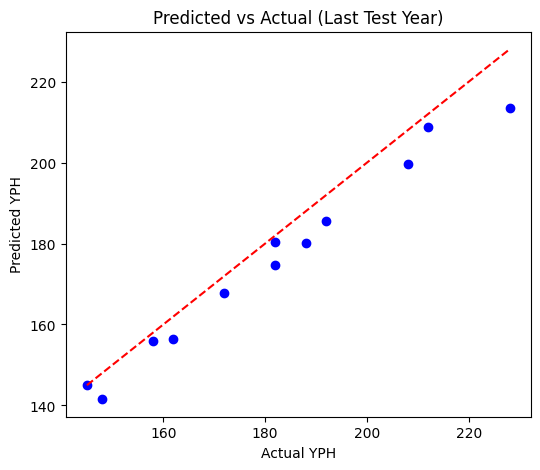

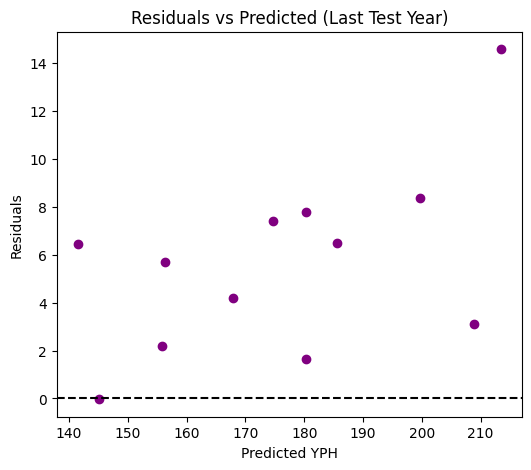

In [79]:
# Results DataFrames
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)

print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df.mean(numeric_only=True))

print("\nAVERAGE TEST METRICS")
print(test_metrics_df.mean(numeric_only=True))

# Feature Importance (Ridge coefficients)
ridge_model = pipeline.named_steps['ridge']
coef_df = pd.DataFrame({
    'feature': features,
    'coefficient': ridge_model.coef_
})

# Calculate absolute percentages
coef_df['abs_coef'] = coef_df['coefficient'].abs()
coef_df['percentage'] = (coef_df['abs_coef'] / coef_df['abs_coef'].sum()) * 100

# Sort by absolute coefficient descending
coef_df = coef_df.sort_values(by='abs_coef', ascending=False)

# Plot feature importance
plt.figure(figsize=(8,6))
bars = plt.barh(coef_df['feature'], coef_df['coefficient'], color='orange')
plt.gca().invert_yaxis()
plt.xlabel("Coefficient Value")
plt.title("Ridge Feature Importance with % Contribution")

# Add percentage labels to the bars
for bar, pct in zip(bars, coef_df['percentage']):
    plt.text(bar.get_width() + np.sign(bar.get_width())*0.02, bar.get_y() + bar.get_height()/2,
             f"{pct:.1f}%", va='center')

plt.show()

# Predicted vs Actual (last test year)
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_test_pred, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title("Predicted vs Actual (Last Test Year)")
plt.show()

# Residuals vs Predicted
residuals = y_test - y_test_pred
plt.figure(figsize=(6,5))
plt.scatter(y_test_pred, residuals, color='purple')
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title("Residuals vs Predicted (Last Test Year)")
plt.show()

### Save Model

In [80]:
# Save path
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/ridge_model.pkl'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the last trained Ridge pipeline
joblib.dump(pipeline, save_path)
print(f"Ridge pipeline saved at: {save_path}")

Ridge pipeline saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/ridge_model.pkl


# **Neural Networks**

### Model Based Preprocessing

In [81]:
# Create copy
df_nn = df.copy()

# YPH lags (1, 12 months)
for lag in [1, 12]:
    df_nn[f'YPH_lag{lag}'] = df_nn['YPH'].shift(lag).bfill()

# Fertilizer lags (1 month)
for fert in ['Compost']:
    df_nn[f'{fert}_lag1'] = df_nn[fert].shift(1).fillna(0)

# Target & Features
target = 'YPH'
features = [col for col in df_nn.columns if col not in ['YPH', 'Year','Compost']]

# Walk-forward validation
TEST_YEARS = sorted(df_nn[df_nn['Year'] >= 2020]['Year'].unique())
WINDOW_SIZE = 3

# Metric storage
train_results = []
test_results = []

### Model Training

In [82]:
for test_year in TEST_YEARS:
    # 1. Data Selection
    train_years = [test_year - i for i in range(WINDOW_SIZE, 0, -1)]
    train_df = df_nn[df_nn['Year'].isin(train_years)].copy()
    test_df  = df_nn[df_nn['Year'] == test_year].copy()

    X_train, y_train = train_df[features].values, train_df[target].values
    X_test, y_test   = test_df[features].values, test_df[target].values

    # 2. Scaling (Both X and y)
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train)
    X_test_scaled  = scaler_X.transform(X_test)

    # Scale Y - important for NN performance
    y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()

    # 3. Model Definition
    model = Sequential([
        Dense(16, activation='relu', kernel_initializer='he_normal', input_shape=(X_train_scaled.shape[1],)),
        Dropout(0.2),
        Dense(8, activation='relu'),
        Dense(1)
    ])

    # Use a specific learning rate
    model.compile(optimizer=Adam(learning_rate=0.01), loss='mse')

    model.fit(
        X_train_scaled, y_train_scaled,
        epochs=100,
        batch_size=4,
        verbose=0
    )

    # 5. Predictions & Inverse Scaling
    y_train_pred_scaled = model.predict(X_train_scaled)
    y_test_pred_scaled  = model.predict(X_test_scaled)

    # Bring values back to original scale (e.g., from 0.5 back to 140.0)
    y_train_pred = scaler_y.inverse_transform(y_train_pred_scaled).flatten()
    y_test_pred  = scaler_y.inverse_transform(y_test_pred_scaled).flatten()

    # 6. Store metrics (Using unscaled y values)
    train_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_train, y_train_pred)),
        'mae': mean_absolute_error(y_train, y_train_pred),
        'mse': mean_squared_error(y_train, y_train_pred),
        'r2': r2_score(y_train, y_train_pred)
    })

    test_results.append({
        'year': test_year,
        'rmse': np.sqrt(mean_squared_error(y_test, y_test_pred)),
        'mae': mean_absolute_error(y_test, y_test_pred),
        'mse': mean_squared_error(y_test, y_test_pred),
        'r2': r2_score(y_test, y_test_pred)
    })

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


...

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step


### Model Evaluation


TRAIN METRICS PER YEAR
   year      rmse       mae        mse        r2
0  2020  3.254341  2.433071  10.590736  0.981678
1  2021  4.384541  3.396415  19.224201  0.967555
2  2022  4.808705  3.403308  23.123646  0.964020
3  2023  3.493729  2.865384  12.206144  0.982056
4  2024  4.371892  3.518265  19.113436  0.972008
5  2025  4.129873  3.275514  17.055853  0.975114

TEST METRICS PER YEAR
   year       rmse        mae         mse        r2
0  2020   9.681878   8.214324   93.738762  0.844652
1  2021  15.443093  14.309281  238.489136  0.612930
2  2022   8.778364   7.753526   77.059677  0.874931
3  2023   8.157399   6.245648   66.543159  0.892000
4  2024  12.361364  10.168859  152.803329  0.753042
5  2025   9.646637   8.298786   93.057610  0.849602

AVERAGE TRAIN METRICS
year    2022.500000
rmse       4.073847
mae        3.148659
mse       16.885669
r2         0.973738
dtype: float64

AVERAGE TEST METRICS
year    2022.500000
rmse      10.678123
mae        9.165071
mse      120.281946
r2    

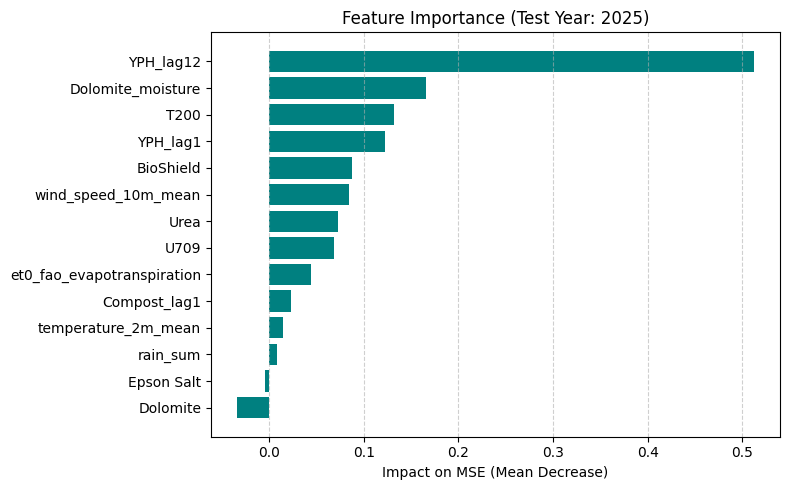

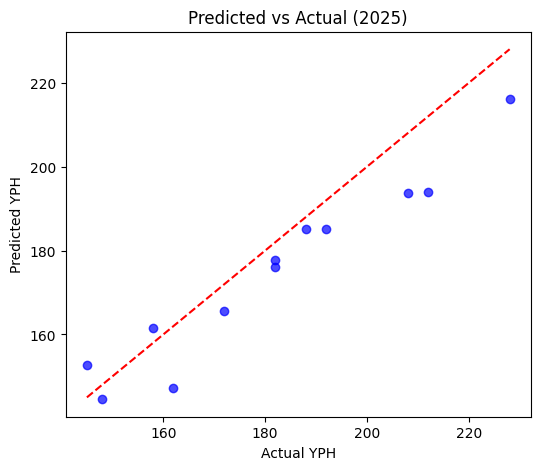

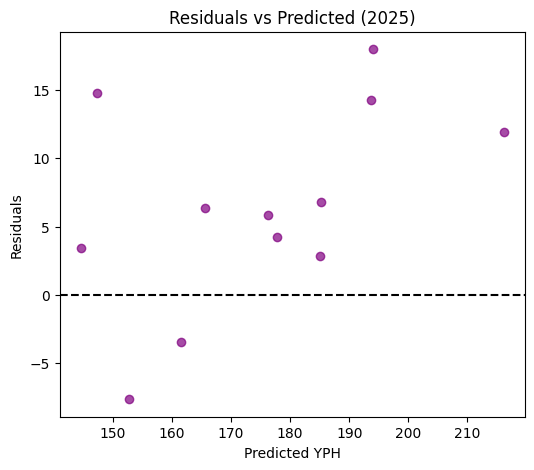

In [88]:
train_metrics_df = pd.DataFrame(train_results)
test_metrics_df  = pd.DataFrame(test_results)

print("\nTRAIN METRICS PER YEAR")
print(train_metrics_df)
print("\nTEST METRICS PER YEAR")
print(test_metrics_df)

print("\nAVERAGE TRAIN METRICS")
print(train_metrics_df.mean(numeric_only=True))
print("\nAVERAGE TEST METRICS")
print(test_metrics_df.mean(numeric_only=True))

# Define a custom scorer
def keras_rmse_scorer(estimator, X, y):
    y_pred = estimator.predict(X, verbose=0)
    return -np.sqrt(mean_squared_error(y, y_pred))

# Calculate Permutation Importance
y_test_scaled = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

perm_importance = permutation_importance(
    model,
    X_test_scaled,
    y_test_scaled,
    scoring=keras_rmse_scorer,
    n_repeats=10,
    random_state=42
)

# DataFrame
importance_df = pd.DataFrame({
    'feature': features,
    'importance': perm_importance.importances_mean
}).sort_values(by='importance', ascending=True)

# Feature Importance Plot
plt.figure(figsize=(8, 5))
plt.barh(importance_df['feature'], importance_df['importance'], color='teal')
plt.xlabel("Impact on MSE (Mean Decrease)")
plt.title(f"Feature Importance (Test Year: {test_year})")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Predicted vs Actual Plot
plt.figure(figsize=(6,5))
plt.scatter(y_test, y_test_pred, color='blue', alpha=0.7)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual YPH")
plt.ylabel("Predicted YPH")
plt.title(f"Predicted vs Actual ({test_year})")
plt.show()

# Residuals vs Predicted
residuals = y_test - y_test_pred
plt.figure(figsize=(6,5))
plt.scatter(y_test_pred, residuals, color='purple', alpha=0.7)
plt.axhline(0, color='black', linestyle='--')
plt.xlabel("Predicted YPH")
plt.ylabel("Residuals")
plt.title(f"Residuals vs Predicted ({test_year})")
plt.show()

### Save Model

In [89]:
# Path to save
save_path = '/content/drive/MyDrive/DSGP_DOCS/Final_Models/nn_model.h5'
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save model
model.save(save_path)
print(f"Neural Network model saved at: {save_path}")

Neural Network model saved at: /content/drive/MyDrive/DSGP_DOCS/Final_Models/nn_model.h5
